In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATED LINK**
https://github.com/gingersknapp/eds220-hwk2


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

In [ ]:
# FINAL CODE



## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [3]:
# a.
#Load packages
import pandas as pd
import numpy as np

# Import data and view the first 5 rows

catch_data = pd.read_csv('data/salmon_data.csv')

catch_data.head()


,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [28]:
# b.
# Identify columns and data types 
catch_data.info()
#Count Null/missing values
catch_data.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   object
dtypes: int64(1), object(4)
memory usage: 333.7+ KB


Region             0
Year               0
notesRegCode    7125
Species            0
Catch              0
dtype: int64

In [44]:
#Investigate why Catch is an object instead of an integer
catch_data[catch_data['Catch'].str.isnumeric()]
catch_data[catch_data['Catch'].str.isalpha()]

,Region,Year,notesRegCode,Species,Catch
400,GSE,1955,NaN,Chinook,I


In [29]:
#Identify how often each species is documented
catch_data['Species'].value_counts()

Species
Chinook    1708
Sockeye    1708
Coho       1708
Pink       1708
Chum       1708
Name: count, dtype: int64

In [82]:
#Identify unique values for region and how often they are reported
catch_data['Region'].value_counts()

Region
KOD    580
NSE    575
BRB    570
SSE    560
CHG    550
PWS    545
CKI    525
BER    510
YAK    480
COP    470
NOP    460
SOP    450
ALU    435
KSK    425
KTZ    415
GSE    410
YUK    395
NRS    185
Name: count, dtype: int64

In [45]:
#Identify the range of years covered in the dataset
print(f"The datasheet includes years from {catch_data['Year'].min()} to {catch_data['Year'].max()}")

The datasheet includes years from 1878 to 1997


In [94]:
#Identify unique values for notesRegCode
print(catch_data['notesRegCode'].value_counts())
print('\n')
print(f"Number or rows where catch is recorded as 0 because no catch was recorded: {catch_data[(catch_data['notesRegCode'] == 'No reported catch') & (catch_data['Catch'] == '0')].shape[0]}")
print(f"Total number of rows where catch is recorded as 0: {catch_data[catch_data['Catch'] == '0'].shape[0]}")

notesRegCode
No reported catch                                                                       385
Estimated from canned production                                                        195
Catches included in S. peninsula catches or none                                        115
Bering River catches included in Copper River catches                                    95
Catches from Unalaksa to Castle Cape                                                     85
Pink and chum catch estimated form canned production; from Castle Cp. To E. boundary     85
Chinook and coho and chum estimated from canned production                               70
Includes Copper River catches                                                            35
Includes Bering River catches                                                            35
Estimated from canned production; includes Aleautian Island catches                      30
Pink and chum catch estimated form canned production               

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

I used `.info()` to determine column names, associated data types, and the total number of missing values in each column.  There are 5 columns in the dataset, including Region, Year, notesRegCode, Speceis, and Catch. There are 8540 rows. Every row has information from Region, Year, species, and Catch, but not for notesRegCode.  There are 7125 rows mssing information for notesRegCode. Year is an integer type, which is usable as is but can also be converted to a datetime.  Catch is an object, suggesting that there may be mis-entered values.  It should likely be a numeric type such as a integer (int64) or float (float64).

I used filtering with `.str.isnumeric` and `.str.isalpha` to identify which rows in the Catch column are numeric characters and alphabetic characters to identify what is causing the column to be classified as an object.  There are 8539 rows where catch is a numeric value and one where it is not.  In Row 400, Catch is entered as I.

I used `catch_data['Species'].value_counts()` to identify how many rows contain information on each species.  Each species occurs 1708 times in the data set.  Five salmon species are recorded (Chinook, Sockeye, Coho, Pink, and Chum).

I used `.value_counts()` to determine how many regions are recorded. There are 18 regions recorded in the dataset, ranging from 185 occurances to 580.  Most regions are recorded between 400 and 600 times.

I used `.min()` and `.max()` for year to determine the range of years covered in the dataset.  The dataset includes reocrds from 1878 to 1997. 

I used `.value_counts` to identify the frequency of unique values in notesRegCode to explore what this column records.  This column appears to include notes on whether any catch was recorded and how values were recorded or estimated. It notes which rows correspond to entries were no catch was recorded. In these instances catch was recorded as 0.  I used filtering and `.shape` to count how many rows recorded Catch as 0 because no catch was recorded, and to count how many total rows recorded catch as 0.  There are a total of 2571 rows where catch is 0, 385 of which document instances where no catch was recorded.

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [97]:
# Save unique notes in `notesRegCode` as a list
notes_unique = catch_data['notesRegCode'].unique()
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [98]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [101]:
# Remove the `notesRegCode` column from the dataframe
catch_data = catch_data.drop(columns = 'notesRegCode')

In [102]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


Catch does not have the expected data type. It is classified as an object when it should likely be classified as an integer (int64).

Year is expected and usable as an integer, but it may be useful to covert it to a datetime.

Region and Species have the expected data types of objects.

In [103]:
catch_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Region   8540 non-null   object
 1   Year     8540 non-null   int64 
 2   Species  8540 non-null   object
 3   Catch    8540 non-null   object
dtypes: int64(1), object(3)
memory usage: 267.0+ KB


<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [104]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [105]:
# Locate row where Catch is reported as "I" instead of 1
catch_I = catch_data[catch_data['Catch'] == "I"]
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [106]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [124]:
# Convert the value I in catch to 1
catch_data.iloc[400, 3] = catch_data.iloc[400, 3].replace("I", '1')

#Confirm the change
catch_1 = catch_data.iloc[400, :]
#Print catch_1
catch_1

Region         GSE
Year          1955
Species    Chinook
Catch            1
Name: 400, dtype: object

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [125]:
#Convert the Catch column type to integer (int64)
catch_data['Catch'] = catch_data['Catch'].astype('int64')

#Confirm change
catch_column_type = catch_data['Catch'].dtype
catch_column_type

dtype('int64')

In [126]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [130]:
# Obtain average salmon catches per region
avg_region = catch_data.groupby('Region')['Catch'].mean()
avg_region

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64

In [131]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<Axes: title={'center': 'Commercial salmon catch by region between 1878 and 1997'}, xlabel='Region', ylabel='Mean salmon catch (thousand of fish)'>

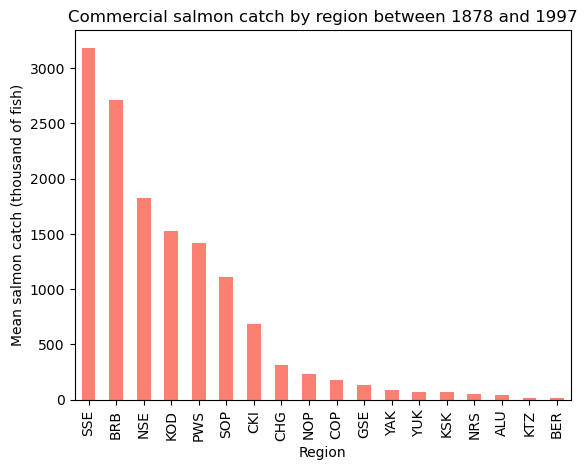

In [143]:
(avg_region.sort_values(ascending = False)                   # Sort by descending means
            .plot(
                kind = 'bar',
                title = 'Commercial salmon catch by region between 1878 and 1997',
                xlabel = 'Region',
                ylabel = 'Mean salmon catch (thousand of fish)',
                color = 'salmon'
            )
)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [ ]:
grader.check_all()